# Cosmological zoom-in — Part 2: dark-matter-only zoom and decontamination

| Step | Code | What it does | Part |
|---|---|---|---|
| 1–3 | MUSIC2, RAMSES, hast | Parent box, halo selection | 1 |
| 4 | MUSIC2 | Dark-matter-only zoom ICs around the Lagrangian region | **2** |
| 5 | RAMSES | Dark-matter-only zoom run | **2** |
| 6 | hast | Decontaminate: recompute the Lagrangian region from the zoom run | **2** |
| 7–8 | MUSIC2, RAMSES | Zoom with baryons | 3 |

We zoom on halo 2 of Part 1 (`MyFirstZoom/Selection/results/music_zoom_2`), with `levelmax = 9`, i.e. an effective resolution of $512^3$. The codes are the same as in Part 1.

## 4. Zoom initial conditions

### 4.1. MUSIC parameter file

The configuration file to generate zoom initial conditions for halo 2 is `MyFirstZoom/ZoomDM/ICs/music.conf`. It is the parent `music.conf` of Part 1 with these changes:

| Parameter | Parent box | Zoom | Why |
|---|---|---|---|
| `levelmax` | 7 | 9 | Two nested levels inside the Lagrangian region. Each level is 8× lighter: $m_p = 1.5\times10^{7}\,M_\odot$ at level 9, so a $2\times10^{12}\,M_\odot$ halo has $\sim10^5$ particles. |
| `region`, `region_point_file` | absent | `convex_hull`, `../../Selection/results/music_zoom_2` | MUSIC refines inside the convex hull of the points written by hast. |
| `seed[8]`, `seed[9]` | absent | set | New small-scale modes on the refined levels. **`seed[7]` is unchanged**, so the large-scale modes, and the halo, are those of the parent box. |
| `levelmin_TF` | – | 8 | MUSIC computes the density field one level above `levelmin`. |
| `padding`, `overlap` | 0 | 16, 4 | Size of the buffer around each refined level, and of the overlap used to match the levels. |
| `[poisson]` | `fft_fine`, `accuracy` | + `pre_smooth`, `post_smooth`, `smoother` | Settings of the multigrid solver used on the nested levels. |

`zstart`, `boxlength` and the cosmology must be identical to the parent box.

### 4.2. Running MUSIC

```bash
cd MyFirstZoom/ZoomDM/ICs
$MUSICPATH/MUSIC music.conf
```

This writes `ics_zoom_dm/level_007/` … `level_009/` and `music.conf_log.txt`.

IMPORTANT:--> **Check three lines of the log:**

```bash
grep -E "are refined|shifted by|particle mass" music.conf_log.txt
```

1. **`… of cells on level N are refined` must be non-zero.** If it is `0.000000`, the refinement mask is empty and RAMSES will run a uniform $128^3$ box instead of a zoom. With upstream MUSIC2 this happens for many point sets, because of a numerical problem in the convex hull; this is why we use the [luturonunca/MUSIC2](https://github.com/luturonunca/MUSIC2) fork for now.
2. **`Domain will be shifted by (i, j, k)`: write it down.** MUSIC moves the zoom region to the centre of the box, by an integer number of level-7 cells. Here it is (−37, 21, 24). All positions in the zoom run are in this shifted frame, and step 6 needs this shift to bring them back.
3. **`particle mass`** of the finest level: $1.02\times10^7\,h^{-1}M_\odot$.

## 5. Dark-matter-only zoom run

### 5.1. RAMSES namelist

The namelist file to run the first zoomed DMO run is `MyFirstZoom/ZoomDM/Run/ramses.nml`. Compared with the parent run of Part 1:

| Parameter | Parent | Zoom | Why |
|---|---|---|---|
| `initfile(1:3)` | 1 level | levels 7, 8, 9 | One entry per MUSIC level. |
| `levelmax` | 7 | 18 | The ICs end at level 9. |
| `m_refine` | `11*8.` | `12*8.` | One value per level from `levelmin` to `levelmax − 1`: refine a cell when it holds more than 8 particle masses. |
| `mass_cut_refine` | $2\cdot2^{-21}$ | $2\cdot2^{-27} = 1.49\times10^{-8}$ | Twice the mass (in units of the box mass) of a finest particle. Heavier particles never trigger refinement, so only the high-resolution region refines. MUSIC writes this value for the ICs in `ics_zoom_dm/ramses.nml` if `ramses_nml=yes`. |
| `nexpand` | 1 | `4,1,1` | Number of cells added around the refined region on each initial level. MUSIC suggests `7,1,1`; we use 4 |
| `nsubcycle` | `1,1,2` | `1,1,1,1,2` | Taken from `ics_zoom_dm/ramses.nml`. |
| `&CLUMPFIND_PARAMS` | 8 / 20 / 10 | 80 / 200 / 100 | See below. |
| `ngridtot`, `nparttot` | 1e6, 1e7 | 3e6, 1e7 | More octs for the deeper AMR hierarchy. |

**Why the clump finder thresholds change.** In the parent box, a Milky-Way-mass halo is only a few level-7 cells across, so the finder must accept low densities: cells above 8× the mean density (`density_threshold`), peaks merged into halos when the saddle is denser than 20× (`saddle_threshold`), clumps of more than 10 particles (`mass_threshold`). The zoom resolves the halo with 64× lighter particles and many more cells. With the parent thresholds, the "halo" would extend out to 8× the mean density, well beyond its virial radius, and thousands of 10-particle clumps would be written. The zoom thresholds put the halo boundary close to the virial overdensity (saddle at 200× the mean) and keep only clumps with more than 100 particles. `mass_threshold` is in units of the **smallest** particle mass, i.e. the high-resolution particles here.

### 5.2. Running RAMSES

```bash
cd MyFirstZoom/ZoomDM/Run
mpirun -np 16 $RAMSESPATH/ramses3d ramses.nml > run.log
```

**Check that the zoom levels were loaded:** the number of particles must be larger than the $128^3 = 2\,097\,152$ particles of the parent box.

```bash
grep DM output_00001/header_00001.txt
grep -A10 "Initial mesh structure" run.log | grep -E "Level +(7|8|9) "
```

expect something like 2,436,379 particles, and levels 8 and 9 exist from the start. The run takes about 2.5 hours on 16 cores and writes 16 GB (41 outputs).

### 5.3. A first look at the zoom

As in the Cosmological-Volume tutorial, we load the outputs with yt. yt needs `f90nml` to read RAMSES outputs. The paths are relative to this notebook.

In [ ]:
import yt

yt.funcs.mylog.setLevel("ERROR")  # Stop yt from being too verbose

import matplotlib

matplotlib.rcParams.update({"font.size": 20})
matplotlib.rcParams["figure.facecolor"] = "w"

import numpy as np
import f90nml  # To load RAMSES data in yt

**Initial conditions.** Output 1 is the start of the run ($z = 100$). A zoom has one particle mass per MUSIC level:

In [ ]:
snap = 1
snapstr = "%05d" % snap
path = "MyFirstZoom/ZoomDM/Run/"
ds = yt.load(path + "output_" + snapstr + "/info_" + snapstr + ".txt")

# Access data
ad = ds.all_data()
m_part, n_part = np.unique(ad[("all", "particle_mass")].to("Msun"), return_counts=True)
for m, n in zip(m_part, n_part):
    print("%.3e Msun: %8d particles" % (m, n))

```
1.511e+07 Msun:   220352 particles
1.209e+08 Msun:   139792 particles
9.673e+08 Msun:  2076235 particles
```

Levels 9, 8 and 7: each level is 8 times lighter than the one below, and level 7 is the particle mass of the parent box of Part 1. The total is the 2,436,379 particles of the header.

A density map is not useful here: at $z = 100$ the matter is almost uniform. Instead, we map the mean particle mass along the line of sight (`weight_field`), which shows the nested levels. The cube of level 8 surrounds the convex hull of level 9, at the centre of the box because MUSIC shifted the region there (4.2).

In [ ]:
p = yt.ParticlePlot(
    ds,
    "particle_position_x",
    "particle_position_y",
    "particle_mass",
    weight_field=("all", "particle_ones"),
)
p.set_figure_size((5, 5))
p.set_buff_size(128)
p.set_unit("particle_mass", "Msun")
p.set_axes_unit("Mpccm/h")
p.show()

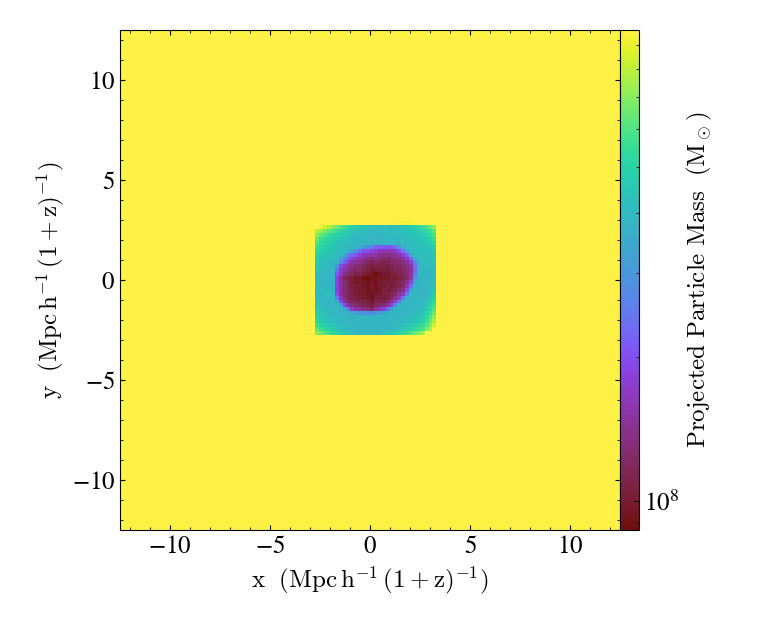

**Last output ($z = 0$).** We keep only the high-resolution particles with a yt particle filter, selecting the lightest particle mass:

In [ ]:
snap = 41
snapstr = "%05d" % snap
ds = yt.load(path + "output_" + snapstr + "/info_" + snapstr + ".txt")

m_hr = ds.all_data()[("all", "particle_mass")].min()


def high_res(pfilter, data):
    return data[(pfilter.filtered_type, "particle_mass")] <= 1.01 * m_hr


yt.add_particle_filter(
    "high_res", function=high_res, filtered_type="all", requires=["particle_mass"]
)
ds.add_particle_filter("high_res")

ad = ds.all_data()
print(ad[("high_res", "particle_mass")].size, "high-resolution particles")
center = ad[("high_res", "particle_position")].mean(axis=0)

p = yt.ParticlePlot(
    ds,
    ("high_res", "particle_position_x"),
    ("high_res", "particle_position_y"),
    ("high_res", "particle_mass"),
    center=center,
    width=(8, "Mpc"),
    density=True,
)
p.set_figure_size((5, 5))
p.set_buff_size(512)
p.set_unit(("high_res", "particle_mass"), "Msun/kpc**2")
p.show()

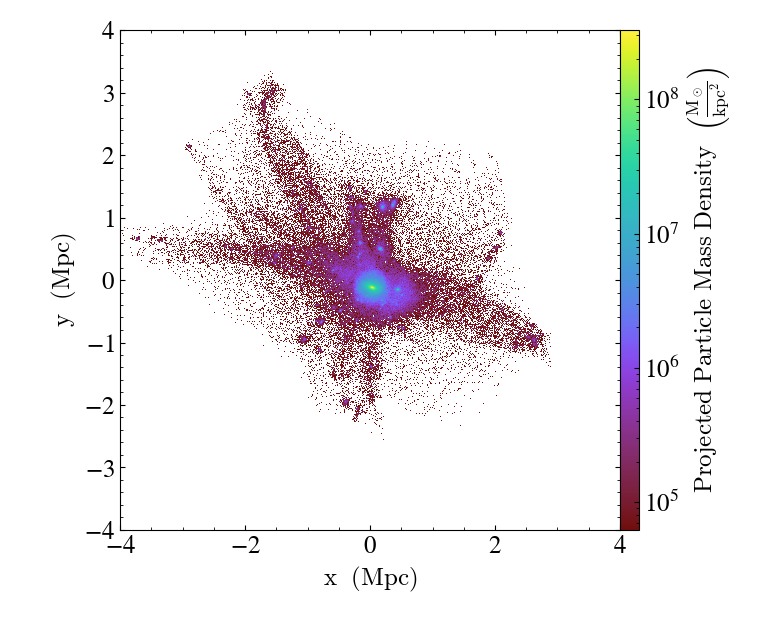

The high-resolution particles now trace the halo and the filaments that feed it, a few Mpc across. Whether coarser particles have also fallen into the halo is the question of the next section.

## 6. Decontamination with hast

### 6.1. Why

The Lagrangian region of Part 1 was computed from the parent box, where the halo was resolved with $\sim10^3$ particles. In the zoom, some low-resolution (heavy) particles from outside the region still end up inside the halo. They *contaminate* it: they scatter the light particles and spoil the halo's inner structure. hast `decontaminate` follows the halo through the outputs of the zoom run, finds the particles that really end up in it, and writes a new region at $z_\mathrm{init}$ for the next ICs.

### 6.2. Parameters

To run the decontamination with hast use the example configuration file: `MyFirstZoom/ZoomDM/Decontaminate/decontaminate.conf`.

- `halo_num = 1`: the target is the most massive halo of the zoom, which is the halo of the high-resolution region, not related to the selection part.
- `rvir = 2.0`: particles within $2\,R_{200}$ at $z=0$ are traced back to $z_\mathrm{init}$.
- `rexclude = 30` kpc: low-resolution particles that come this close to the centre are contaminants.
- **`point_shift = -37, 21, 24` and `point_shift_lmin = 7`**: the MUSIC shift of step 4.2, in level-7 cells. hast subtracts `point_shift / 2**point_shift_lmin` from the positions, which brings them back to the frame of the parent box. Without it, the new region would be centred on the right halo in the *shifted* frame of this run, i.e. on the wrong place in the parent box, and the next zoom would miss the halo. `point_shift_lmin` must be the `levelmin` of the zoom (7), not 1.
- `rotation_curves`, `halo_dynamics`, `lagrange_iords`, `merger_tree`: experimental diagnostics meant to guide a more specific selection, for now they are switched off.

hast writes two regions:

| File | Convex hull (at $z_\mathrm{init}$) of | Use |
|---|---|---|
| `results_part` | high-resolution particles within $2\,R_{200}$, plus low-resolution particles that came within `rexclude` | Tighter region rebuilt around the halo. Can be smaller than the original. |
| `results_part_wide` | **all** high-resolution particles of this zoom, plus every low-resolution particle that entered $R_{200}$ | The original region grown to include the contaminants. It never shrinks. |

We use **`results_part_wide`**: it is the conservative choice and guarantees that the next zoom contains at least the current high-resolution region.

### 6.3. Running hast

```bash
cd MyFirstZoom/ZoomDM/Decontaminate
python $HASTPATH/examples/decontaminate.py decontaminate.conf | tee hastlog.log
```

The output `results_part_wide` (three columns $x, y, z$ in parent-box units, at $z_\mathrm{init}$) is the region for Part 3. hast takes about 6 minutes.

### 6.4. What to look at in `hastlog.log`

For each output, from $z=0$ backwards, hast prints the tracked halo and its contamination. At $z=0$ (`snap 41`):

```
| snap 41 | M200                      = 2.00e+12 Msol
| snap 41 | npart_tot(r<R200)         = 132047
| snap 41 | npart_coarse(r<2.0*R200)  = 62
| snap 41 | contamination(r<2.0*R200) = 0.3%
| snap 41 | Rexclude contaminants     = 0
| snap 41 | r_min coarse part/R200    = 1.390e-01
```

- The halo has $M_{200} = 2.0\times10^{12}\,M_\odot$ and $1.3\times10^5$ particles within $R_{200}$.
- 62 low-resolution particles are within $2\,R_{200}$ (0.3% of the particles), and the closest is at $0.14\,R_{200}$, about 55 kpc. None came within `rexclude` = 30 kpc at any output. The contamination is 0% at early times and grows after $z \approx 1$.
- **Check the shift-back.** The new region must be centred where the old one was, in parent-box coordinates:

| Region | Points | Centroid | Extent |
|---|---|---|---|
| `Selection/results/music_zoom_2` (Part 1) | 167 | (0.798, 0.332, 0.318) | 0.155 × 0.132 × 0.124 |
| `results_part_wide` | 576 | (0.797, 0.337, 0.315) | 0.162 × 0.137 × 0.131 |

The centroids agree, so `point_shift` was applied correctly. With a missing or wrong `point_shift`, the centroid would sit near the box centre (0.5, 0.5, 0.5), where MUSIC had moved the region. The new region is slightly larger: it now includes the 62 contaminants.

### 6.5. Diagnostic plots

hast writes `results_decontamination.pdf`. Its three pages are shown below. Positions are in the frame of the zoom run, i.e. shifted by MUSIC: the zoom region sits near the box centre (18.7 cMpc).

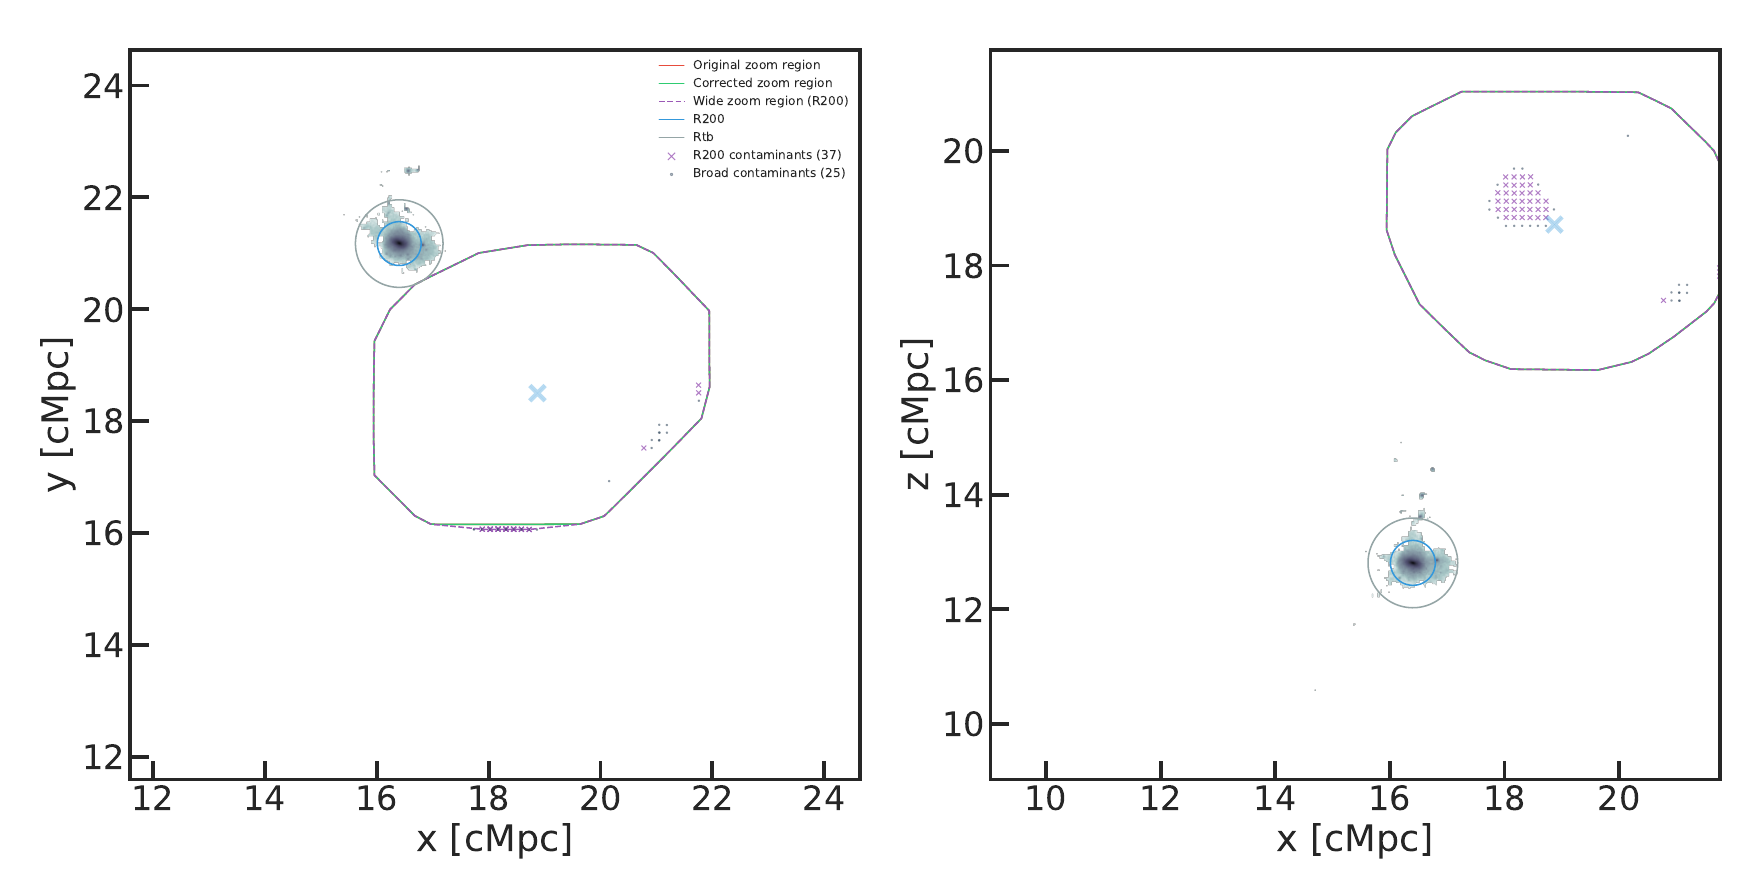

*Page 1.* The halo at $z=0$ with its $R_{200}$ (circle), and the zoom regions at $z_\mathrm{init}$: the original region of Part 1, the corrected region (`results_part`) and the wide region (`results_part_wide`). Crosses are low-resolution particles that entered $R_{200}$ at some output (37); dots are the other low-resolution particles within $2\,R_{200}$ (25). The regions are at $z_\mathrm{init}$ and the halo at $z=0$, so they do not overlap: the halo has moved since $z=100$. The contaminants sit at the edge of the original region; the wide region is grown to include them.

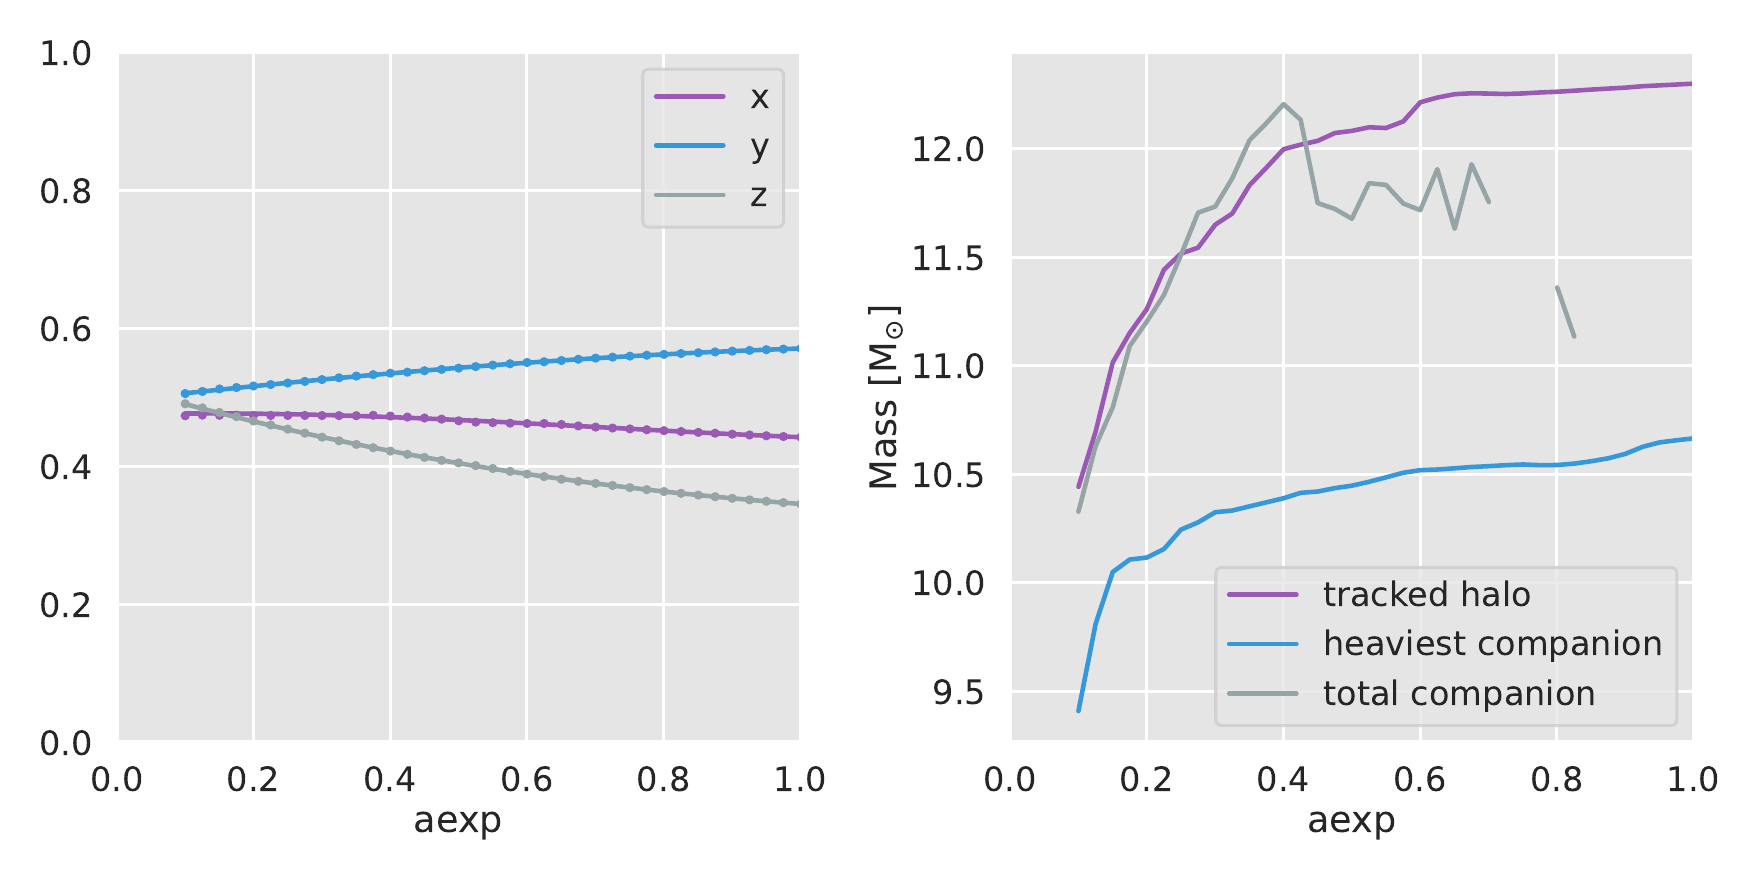

*Page 2.* Left: position of the tracked halo (box units) against the expansion factor $a$. Right: mass (log, $M_\odot$) of the tracked halo, of its heaviest companion and of all companions. The halo grows to $\sim2\times10^{12}\,M_\odot$ by $a\approx0.6$ and is quiet afterwards. The companions are much lighter than the halo after $a\approx0.4$.

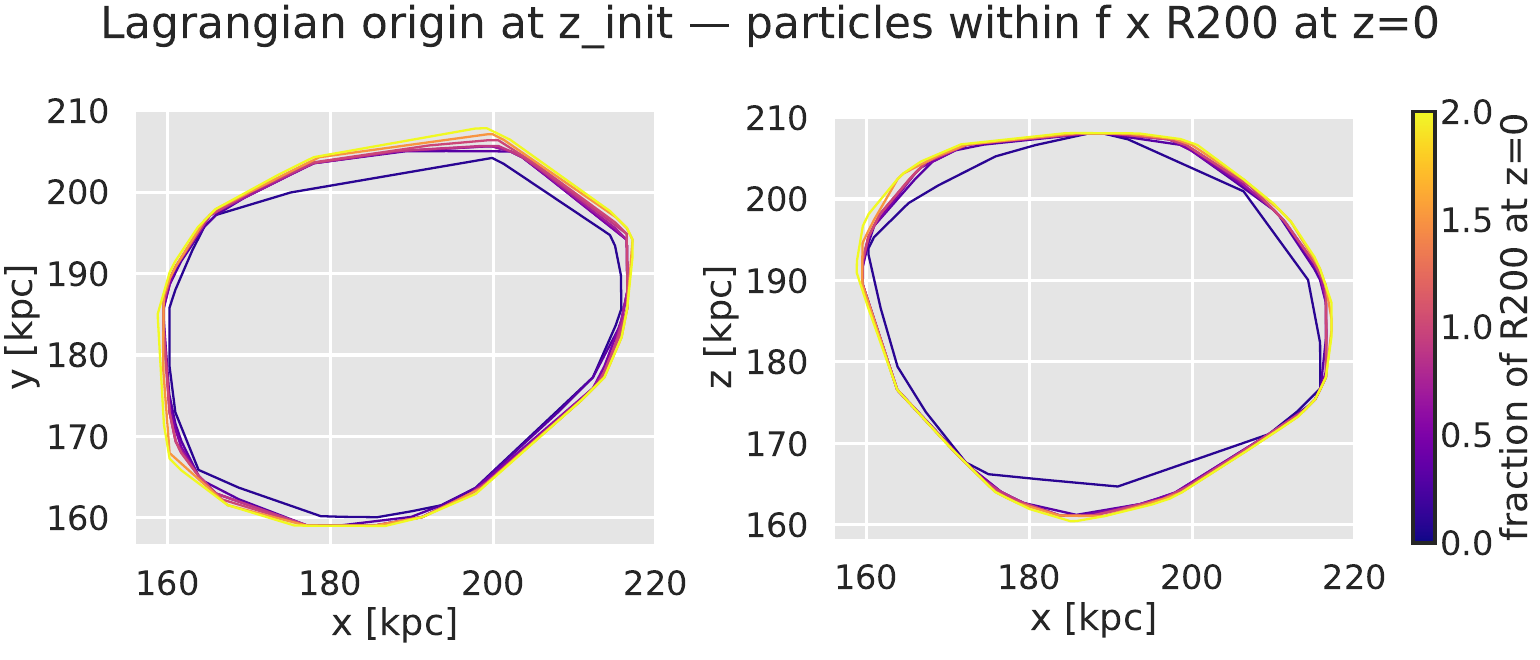

*Page 3.* Convex hulls at $z_\mathrm{init}$ (physical kpc) of the particles that end up within $f\times R_{200}$ at $z=0$, for $f$ from 0 to 2 (colour). The hulls nest tightly: most of the Lagrangian volume of the halo is already set by its inner particles, and going from $R_{200}$ to $2\,R_{200}$ adds little.

---
**Production settings.** Same pipeline with `levelmax = 11` in MUSIC (effective $2048^3$, $m_p = 2.3\times10^{5}\,M_\odot$), five `initfile` levels, `levelmax = 20`, `nexpand = 4,4,4,1,1`, `mass_cut_refine = 2.32831e-10`, `m_refine = 13*8.`, `nsubcycle = 1,1,1,1,1,1,2`.